In [31]:
import sys # for automation and parallelization: set manual to false when run by a launcher
import json
MANUAL, SCENARIO = (True, 'base') if 'ipykernel' in sys.argv[0]\
     else (False, json.loads(sys.argv[1])['scenario'])

In [32]:
import sys
sys.path.insert(0, r'../../../quetzal')

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from typing import Callable
import warnings

from quetzal.io import excel
from quetzal.model import stepmodel, connectionscanmodel
from scipy import sparse
from scipy.spatial.distance import cdist
from scipy.stats import wasserstein_distance

import matplotlib.pyplot as plt

In [33]:
qpath = r'../../'
ipath = qpath + r'inputs/'
mpath = qpath + r'scenarios/{}/models/'.format(SCENARIO)

In [34]:
var = excel.read_var(ipath + r'parameters.xlsx', scenario=SCENARIO)

# COEF GENERATION
ALPHA_HOUSEHOLD = var['step_generation']['alpha_household']
ALPHA_WORKPLACE = var['step_generation']['alpha_workplace']

# COEF MORNING TRAVEL
COEFF_MORNING = var['step_generation']['coeff_morning']

# COEF DISTRIBUTION
INTRA_AREA_TO_DISTANCE_FACTOR = var['step_distribution']['intra_area_to_distance_factor']

DISTRIBUTION_POWER = var['step_distribution']['distribution_power']
INTRAZONAL_SPEED = var['step_distribution']['intrazonal_speed'] # for intrazonal time

# EXTERNAL_MATRIX
EXTERNAL_PT_SHARE = var['step_generation']['external_pt_share']

# MOTO / OCCUPANCY
MOTORCYCLE_SHARE = var['step_generation']['motorcycle_share']
PV_OCCUPANCY_RATE = var['step_generation']['pv_occupancy_rate']
MOTORIZATION_RATE_FACTOR = var['step_generation']['motorization_rate_factor']

In [35]:
if var['run_mode']['mode'] != 'timetables':
    sm = stepmodel.read_zippedpickles(mpath + r'pathfinders')
else:
    sm = connectionscanmodel.read_zippedpickles(mpath + r'pathfinders')

zone_to_road: 100%|██████████| 22/22 [00:02<00:00,  7.80it/s]    


In [36]:
len(sm.zones)

68

# Génération

Already included in zone inputs

In [37]:
sm.zones.drop(columns=['attractions', 'emissions'], inplace=True)

In [38]:
### Waiting for generation factors
sm.zones['emission'] = sm.zones['nb household']
sm.zones['attraction'] = sm.zones['nb workplaces']*(sm.zones['nb household'].sum()/sm.zones['nb workplaces'].sum())

# Distribution

In [39]:
sm.zones[['attraction', 'emission']].sum()

all_los = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [sm.zones.index, sm.zones.index],
        names=['origin', 'destination']
    )
)

deterrence_matrix = all_los.join(
    sm.los.loc[sm.los['pathfinder_session'].isin(['car_aon', 'intrazonal'])].groupby(['origin', 'destination'])['length'].min()
).fillna(1e9)

In [40]:
deterrence_matrix.reset_index(inplace=True)
nodes = pd.Index(deterrence_matrix["origin"].drop_duplicates())

index = {node: i for i, node in enumerate(nodes)}

D = np.full((len(nodes), len(nodes)), np.inf)
np.fill_diagonal(D, 0)

for source, target, distance in deterrence_matrix[["origin", "destination", "length"]].itertuples(index=False, name=None):
    D[index[source], index[target]] = distance/1000

In [41]:
attractions = sm.zones['attraction'].sum()
emissions = sm.zones['emission'].sum()

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def empirical_cdf(x):
    """
    Compute empirical CDF from a 1D array.
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    
    if x.ndim != 1:
        raise ValueError("Input must be a 1D array.")
    if len(x) == 0:
        raise ValueError("Input array is empty.")
    
    x_sorted = np.sort(x)
    n = len(x_sorted)
    cdf = np.arange(1, n + 1) / n
    return x_sorted, cdf

def empirical_survival(x):
    """
    Compute empirical survival function S(x) = 1 - F(x).
    Removes the last point where survival becomes 0, because
    log/fitting often fails there.
    """
    x_sorted, cdf = empirical_cdf(x)
    survival = 1.0 - cdf
    
    mask = survival > 0
    return x_sorted[mask], survival[mask]

def exp_decay(x, a, b):
    return a * np.exp(-b * x)

def power_decay(x, a, b):
    return a * np.power(x, -b)

def fit_survival_models(x):
    """
    Fit empirical survival with:
    - exponential decay
    - power-law decay

    Returns fitted parameters and goodness-of-fit.
    """
    xs, ys = empirical_survival(x)

    results = {}

    # Exponential fit
    try:
        p0_exp = [1.0, 1.0 / max(np.mean(xs), 1e-6)]
        popt_exp, _ = curve_fit(
            exp_decay, xs, ys, p0=p0_exp, bounds=(0, np.inf), maxfev=20000
        )
        y_exp = exp_decay(xs, *popt_exp)
        sse_exp = np.sum((ys - y_exp) ** 2)
        results["exponential"] = {
            "params": {"a": popt_exp[0], "b": popt_exp[1]},
            "sse": sse_exp,
            "x": xs,
            "y_fit": y_exp,
        }
    except Exception as e:
        results["exponential"] = {"error": str(e)}

    # Power-law fit
    try:
        mask_pos = xs > 0
        xs_pow = xs[mask_pos]
        ys_pow = ys[mask_pos]

        p0_pow = [1.0, 1.0]
        popt_pow, _ = curve_fit(
            power_decay, xs_pow, ys_pow, p0=p0_pow, bounds=(0, np.inf), maxfev=20000
        )
        y_pow = power_decay(xs_pow, *popt_pow)
        sse_pow = np.sum((ys_pow - y_pow) ** 2)
        results["power"] = {
            "params": {"a": popt_pow[0], "b": popt_pow[1]},
            "sse": sse_pow,
            "x": xs_pow,
            "y_fit": y_pow,
        }
    except Exception as e:
        results["power"] = {"error": str(e)}

    return xs, ys, results

def plot_fits(x):
    xs, ys, results = fit_survival_models(x)

    plt.figure(figsize=(8, 5))
    plt.scatter(xs, ys, s=30, label="Empirical survival", color="black")

    if "params" in results.get("exponential", {}):
        xfit = np.linspace(xs.min(), xs.max(), 400)
        p = results["exponential"]["params"]
        plt.plot(
            xfit, exp_decay(xfit, p["a"], p["b"]),
            label=f"Exponential: S(x)={p['a']:.3f} exp(-{p['b']:.3f} x)",
            color="red"
        )

    if "params" in results.get("power", {}):
        xfit = np.linspace(max(xs.min(), 1e-6), xs.max(), 400)
        p = results["power"]["params"]
        plt.plot(
            xfit, power_decay(xfit, p["a"], p["b"]),
            label=f"Power: S(x)={p['a']:.3f} x^(-{p['b']:.3f})",
            color="blue"
        )

    plt.xlabel("x")
    plt.ylabel("Survival S(x) = 1 - F(x)")
    plt.title("Empirical survival and fitted decay models")
    plt.grid(True)
    plt.legend()
    plt.show()

    return results

def impedence_func(x):
    """
    Fit empirical survival with:
    - exponential decay
    - power-law decay

    Returns fitted parameters and goodness-of-fit.
    """
    xs, ys = empirical_survival(x)

    p0_exp = [1.0, 1.0 / max(np.mean(xs), 1e-6)]
    popt_exp, _ = curve_fit(
        exp_decay, xs, ys, p0=p0_exp, bounds=(0, np.inf), maxfev=20000
    )

    return lambda x: popt_exp[0]*popt_exp[1]*np.exp(-popt_exp[1]*x)

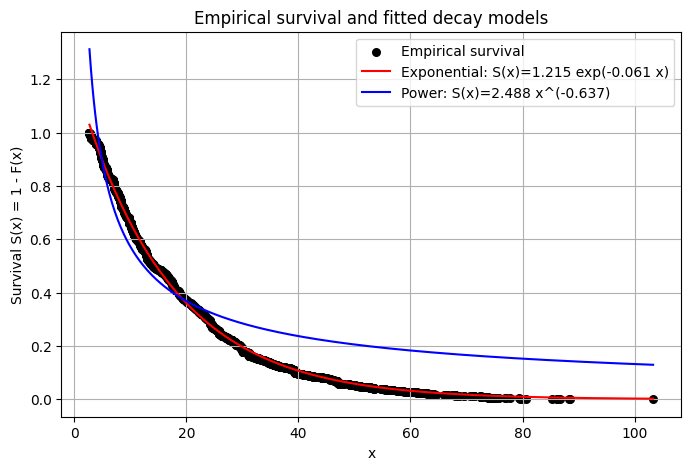

In [43]:
distances_array = pd.read_csv('../../inputs/EMT/distance_dist.csv')['distance'].values/1000
res = plot_fits(distances_array)['exponential']['params']
impedence_func_ = lambda x: res['a']*np.exp(-res['b']*x)

## Optimizing using scipy

In [44]:
def generate_od_matrix(
    gdf: gpd.GeoDataFrame,
    emissions_col: str,
    attractions_col: str,
    distance_func: Callable[[np.ndarray], np.ndarray],
    dist_matrix: np.ndarray,
    min_distance_km: float = 0.5,
    max_distance_km: float = None,
    max_iterations: int = 100,
    tolerance: float = 0.01,
    sparsity_threshold: float = 1e-6,
    return_dense: bool = False
) -> sparse.csr_matrix | np.ndarray:
    """
    Génère une matrice OD sparse avec modèle gravitaire doublement contraint.
    
    Parameters
    ----------
    gdf : GeoDataFrame avec zonage H3
    emissions_col : colonne des émissions (population)
    attractions_col : colonne des attractions (emplois + étudiants)
    distance_func : fonction f(d) -> probabilité
    min_distance_km : seuil minimal de distance (élimine les déplacements courts)
    max_distance_km : seuil maximal optionnel
    h3_col : nom de la colonne contenant les index H3
    max_iterations : iterations max pour Furness
    tolerance : tolérance de convergence
    sparsity_threshold : seuil sous lequel mettre à zéro
    return_dense : retourner array dense au lieu de sparse
    
    Returns
    -------
    Matrice OD (sparse CSR ou dense)
    """
    n = len(gdf)
    
    # Vecteurs émissions et attractions
    O = gdf[emissions_col].values.astype(float)
    D = gdf[attractions_col].values.astype(float)
    
    # Normaliser pour que les totaux correspondent
    total_trips = min(O.sum(), D.sum())
    if total_trips == 0:
        warnings.warn("Aucun déplacement à générer (émissions ou attractions nulles)")
        return sparse.csr_matrix((n, n))
    
    # Ajuster pour équilibrer
    O = O * (total_trips / O.sum())
    D = D * (total_trips / D.sum())
    
    print(f"Zones: {n}, Déplacements totaux: {total_trips:,.0f}")
    
    # Masque de validité : distance > min, distance < max (optionnel), pas diagonale
    mask = (dist_matrix >= min_distance_km)
    if max_distance_km is not None:
        mask &= (dist_matrix <= max_distance_km)
    
    valid_pairs = mask.sum()
    print(f"Paires valides après filtrage: {valid_pairs:,} / {n*n:,} ({100*valid_pairs/(n*n):.1f}%)")
    
    # Appliquer la fonction de distance
    print("Application de la fonction de distribution...")
    impedance = np.zeros_like(dist_matrix)
    impedance[mask] = distance_func(dist_matrix[mask])
    
    # Remplacer NaN/Inf
    impedance = np.nan_to_num(impedance, nan=0.0, posinf=0.0, neginf=0.0)
    
    # Algorithme de Furness (IPF - Iterative Proportional Fitting)
    print("FRATAR")
    
    # Initialisation
    T = impedance.copy()
    
    for iteration in range(max_iterations):
        # Contrainte sur les origines
        row_sums = T.sum(axis=1)
        row_sums[row_sums == 0] = 1  # Éviter division par zéro
        row_factors = O / row_sums
        T = T * row_factors[:, np.newaxis]
        
        # Contrainte sur les destinations
        col_sums = T.sum(axis=0)
        col_sums[col_sums == 0] = 1
        col_factors = D / col_sums
        T = T * col_factors[np.newaxis, :]
        
        # Vérifier convergence
        row_error = np.abs(T.sum(axis=1) - O).max()
        col_error = np.abs(T.sum(axis=0) - D).max()
        
        if row_error < tolerance and col_error < tolerance:
            print(f"  Convergence atteinte à l'itération {iteration + 1}")
            break
    else:
        print(f"  Attention: pas de convergence après {max_iterations} itérations")
        print(f"  Erreur résiduelle: lignes={row_error:.2f}, colonnes={col_error:.2f}")

    # Appliquer le seuil de sparsité
    T[T < sparsity_threshold * total_trips / (n * n)] = 0
    
    # Convertir en sparse
    T_sparse = sparse.csr_matrix(T)
    
    # Stats finales
    nnz = T_sparse.nnz
    density = nnz / (n * n)
    print(f"\nMatrice finale:")
    print(f"  Non-zéros: {nnz:,} ({100*density:.2f}% de densité)")
    print(f"  Total déplacements: {T_sparse.sum():,.0f}")
    print(f"  Min/Max par cellule: {T_sparse.data.min():.2f} / {T_sparse.data.max():.2f}")
    
    if return_dense:
        return T
    return T_sparse, T

In [45]:
od_matrix_init, mask = generate_od_matrix(
    gdf=sm.zones,
    emissions_col="emission",
    attractions_col="attraction",
    distance_func=impedence_func_,
    dist_matrix=D,
    min_distance_km=0,
    max_distance_km=2000,
    tolerance=0.1,
    sparsity_threshold=1,
    return_dense=False
)

mask[mask>0] = 1

Zones: 68, Déplacements totaux: 1,675,520
Paires valides après filtrage: 4,624 / 4,624 (100.0%)
Application de la fonction de distribution...
FRATAR
  Convergence atteinte à l'itération 16

Matrice finale:
  Non-zéros: 1,372 (29.67% de densité)
  Total déplacements: 1,291,157
  Min/Max par cellule: 362.42 / 16236.45


In [46]:
min_distance_km = 2
max_distance_km = 140
step = 5

distance_buckets = pd.read_csv('../../inputs/EMT/distance_dist.csv').drop(columns=['Unnamed: 0'])
distance_buckets['distance'] /= 1000
distance_buckets = distance_buckets.loc[distance_buckets['distance'] >= min_distance_km]
distance_buckets = distance_buckets.loc[distance_buckets['distance'] < max_distance_km]
distance_buckets['bucket'] = distance_buckets['distance'].apply(lambda x: ((x+step)//step)*step)
distance_buckets = distance_buckets.groupby('bucket').count().reset_index().rename(columns={'distance': 'total'}).sort_values('bucket')
distance_buckets['percentage'] = distance_buckets['total']/distance_buckets['total'].sum()

In [47]:
def distribution(
    gdf,
    friction_matrix,
    emissions_col,
    attractions_col,
    max_iterations = 30,
    tolerance=0.1,
    h3_col='hex_id',
    verbose=True
) -> sparse.csr_matrix | np.ndarray:
    """
    Génère une matrice OD sparse avec modèle gravitaire doublement contraint.
    
    Parameters
    ----------
    gdf : GeoDataFrame avec zonage H3
    emissions_col : colonne des émissions (population)
    attractions_col : colonne des attractions (emplois + étudiants)
    distance_func : fonction f(d) -> probabilité
    min_distance_km : seuil minimal de distance (élimine les déplacements courts)
    max_distance_km : seuil maximal optionnel
    h3_col : nom de la colonne contenant les index H3
    max_iterations : iterations max pour Furness
    
    Returns
    -------
    Matrice OD (sparse CSR ou dense)
    """
    n = len(gdf)
    
    # Vecteurs émissions et attractions
    O = gdf[emissions_col].values.astype(float)
    D = gdf[attractions_col].values.astype(float)
    
    # Normaliser pour que les totaux correspondent
    total_trips = min(O.sum(), D.sum())
    
    ### # Ajuster pour équilibrer
    ### O = O * (total_trips / O.sum())
    ### D = D * (total_trips / D.sum())
    
    if verbose:
        print(f"Zones: {n}, Déplacements totaux: {total_trips:,.0f}")
    
    # Algorithme de Furness (IPF - Iterative Proportional Fitting)
        print("FRATAR")
    
    # Initialisation
    T = friction_matrix.copy()
    
    for iteration in range(max_iterations):
        # Contrainte sur les origines
        row_sums = T.sum(axis=1)
        row_sums[row_sums == 0] = 1  # Éviter division par zéro
        row_factors = O / row_sums
        T = T * row_factors[:, np.newaxis]
        
        # Contrainte sur les destinations
        col_sums = T.sum(axis=0)
        col_sums[col_sums == 0] = 1
        col_factors = D / col_sums
        T = T * col_factors[np.newaxis, :]
        
        # Vérifier convergence
        row_error = np.abs(T.sum(axis=1) - O).max()
        col_error = np.abs(T.sum(axis=0) - D).max()
        
        if row_error < tolerance and col_error < tolerance:
            if verbose:
                print(f"  Convergence atteinte à l'itération {iteration + 1}")
            break
    else:
        if verbose:
            print(f"  Attention: pas de convergence après {max_iterations} itérations")
            print(f"  Erreur résiduelle: lignes={row_error:.2f}, colonnes={col_error:.2f}")

    
    # Convertir en sparse
    T_sparse = sparse.csr_matrix(T).toarray()

    n_rows, n_cols = T_sparse.shape
    zone_ids = gdf[h3_col].values if h3_col in gdf.columns else gdf.index.values

    return pd.DataFrame({
        "origine": np.repeat(zone_ids, n_cols),
        "destination": np.tile(zone_ids, n_rows),
        "flux": T_sparse.reshape(-1)
    })

In [48]:
def get_trips_by_distance(zonage, exponent, distance_matrix, min_distance_km=min_distance_km, verbose=False):
    #1. Create friction matrix
    friction_matrix = distance_matrix.copy()
    friction_matrix[friction_matrix==0] = 1
    ### friction_matrix = np.power(friction_matrix, -exponent)
    friction_matrix = np.exp(-exponent*friction_matrix)
    friction_matrix = np.clip(friction_matrix, None, 1e9)
    friction_matrix *= mask

    trips_per_distance = distribution(zonage, friction_matrix, emissions_col='emission', attractions_col='attraction', verbose=verbose)

    n_rows, n_cols = distance_matrix.shape
    zone_ids = sm.zones.index.values

    distances_df = pd.DataFrame({
        "origine": np.repeat(zone_ids, n_cols),
        "destination": np.tile(zone_ids, n_rows),
        "distance": distance_matrix.reshape(-1)
    })

    trips_per_distance = trips_per_distance.merge(distances_df, on=['origine', 'destination'], how='left')

    distribution_distance_buckets = trips_per_distance.copy().drop(columns=['origine', 'destination'])
    distribution_distance_buckets['bucket'] = distribution_distance_buckets['distance'].apply(lambda x: ((x+step)//step)*step)
    distribution_distance_buckets = distribution_distance_buckets.drop(columns='distance').groupby('bucket').sum().reset_index().rename(columns={'flux': 'total'}).sort_values('bucket')
    distribution_distance_buckets['percentage'] = distribution_distance_buckets['total']/distribution_distance_buckets['total'].sum()
    return distribution_distance_buckets
    
def difference_with_data(exponent):
    trips_by_distance = get_trips_by_distance(sm.zones, exponent, D, min_distance_km=min_distance_km, verbose=False)
    trips_by_distance = trips_by_distance.loc[trips_by_distance['bucket'] > min_distance_km]
    return wasserstein_distance(distance_buckets['percentage'], trips_by_distance['percentage'])

In [49]:
from scipy.optimize import minimize

alpha_min = minimize(difference_with_data, 5)['x'][0]
print(alpha_min)

-12.512370454713242


### Check

In [50]:
friction_matrix = D.copy()
friction_matrix[friction_matrix==0] = 1
friction_matrix = np.exp(-alpha_min*friction_matrix)
### friction_matrix = np.power(friction_matrix, -alpha_min)
friction_matrix = np.clip(friction_matrix, None, 1e9)
friction_matrix *= mask

OD_matrix_opt = distribution(sm.zones, friction_matrix, emissions_col='emission', attractions_col='attraction', max_iterations=500, tolerance=10, verbose=True)

Zones: 68, Déplacements totaux: 1,675,520
FRATAR
  Attention: pas de convergence après 500 itérations
  Erreur résiduelle: lignes=3336.00, colonnes=0.00


In [51]:
print('total déplacements: ', OD_matrix_opt['flux'].sum())
print('densité: ', 1 - len(OD_matrix_opt.loc[OD_matrix_opt['flux'] == 0])/len(OD_matrix_opt))

total déplacements:  1675520.0
densité:  0.29671280276816614


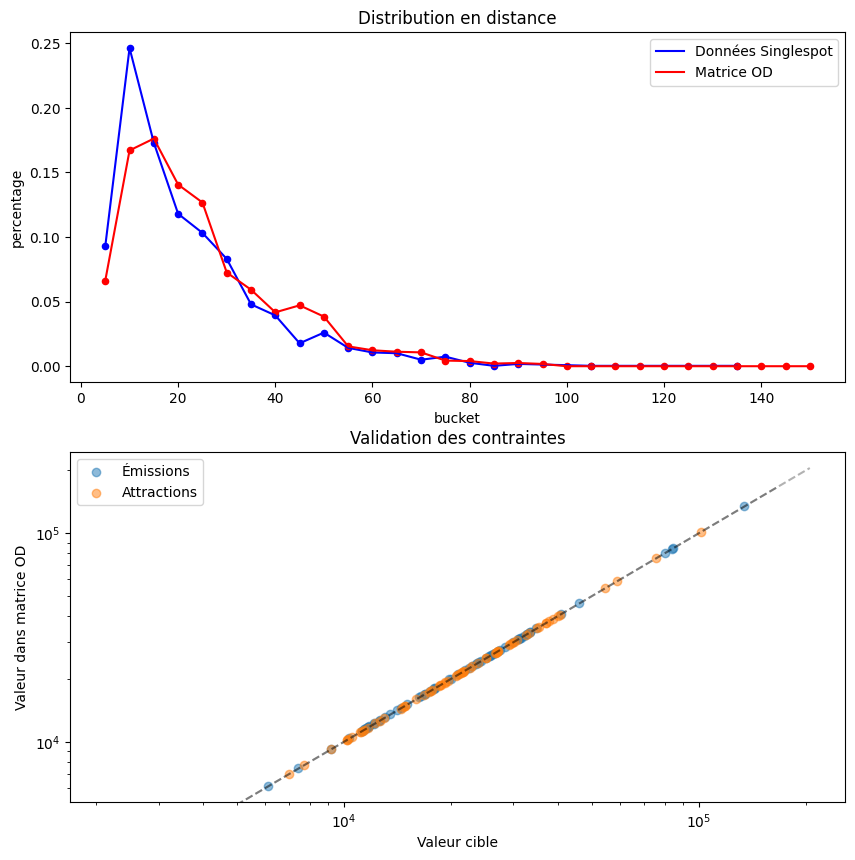

In [52]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ax = axes[0]

trips_by_distance = get_trips_by_distance(sm.zones, alpha_min, D, min_distance_km=min_distance_km, verbose=False)
trips_by_distance = trips_by_distance.loc[trips_by_distance['bucket'] > min_distance_km]

distance_buckets.plot.scatter(x='bucket', y='percentage', color='blue', ax=ax)
distance_buckets.rename(columns={'percentage': 'Données Singlespot'}).plot.line(x='bucket', y='Données Singlespot', color='blue', ax=ax)
trips_by_distance.plot.scatter(x='bucket', y='percentage', color='red', ax=ax)
trips_by_distance.rename(columns={'percentage': 'Matrice OD'}).plot.line(x='bucket', y='Matrice OD', color='red', ax=ax)
ax.set_title("Distribution en distance")

ax = axes[1]
summary = sm.zones.merge(
    OD_matrix_opt.groupby('origine')['flux'].sum().reset_index().rename(columns={'flux': 'from'})
    , left_index=True, right_on='origine'
    ).merge(
        OD_matrix_opt.groupby('destination')['flux'].sum().reset_index().rename(columns={'flux': 'to'})
        , left_on='origine', right_on='destination'
    )[['origine', 'emission', 'from', 'attraction', 'to']]
ax.scatter(summary['emission'], summary['from'], alpha=0.5, label='Émissions')
ax.scatter(sm.zones['attraction'], summary['to'], alpha=0.5, label='Attractions')
ax.set_xlabel("Valeur cible")
ax.set_ylabel("Valeur dans matrice OD")
ax.set_title("Validation des contraintes")

ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
ax.plot([0, ax.get_xlim()[1]], [0, ax.get_xlim()[1]*(min(attractions, emissions)/attractions)], 'k--', alpha=0.3)
ax.plot([0, ax.get_xlim()[1]], [0, ax.get_xlim()[1]*(min(attractions, emissions)/emissions)], 'k--', alpha=0.3)

In [53]:
sm.volumes = OD_matrix_opt.rename(columns={
    'origine': 'origin',
    'flux': 'volume'
}).copy()

In [54]:
summary['gap_origin'] = (summary['emission'] - summary['from'])/summary['emission'].sum()
summary['gap_destination'] = (summary['attraction'] - summary['to'])/summary['attraction'].sum()

# EXPORT

In [55]:
sm.to_zippedpickles(mpath + r'/generation_distribution')

zone_to_road: 100%|██████████| 22/22 [00:05<00:00,  4.15it/s]    


In [56]:
end_of_notebook

NameError: name 'end_of_notebook' is not defined

# insight

In [ ]:
from shapely.geometry import LineString
import numpy as np
intrazone_distances = (sm.zones.area ** 0.5) * INTRA_AREA_TO_DISTANCE_FACTOR
zone_geom = sm.zones['geometry'].centroid.to_dict()

sm.volumes['distance'] = sm.volumes.apply(
    lambda r: LineString([zone_geom[r['origin']], zone_geom[r['destination']]]).length,
    1
)

sm.volumes.loc[sm.volumes['origin']==sm.volumes['destination'], 'distance'] = sm.volumes.loc[sm.volumes['origin']==sm.volumes['destination']].apply(
    lambda x: intrazone_distances[x['origin']], 1
) 

In [ ]:
sm.volumes['volume'] = sm.volumes['pt_captive'] + sm.volumes['car_owners'] + sm.volumes['moto_owners']

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
bins=np.arange(0, 8000, 350)

ax.hist(
    [sm.volumes['distance'], sm.volumes['distance'], sm.volumes['distance']],
    bins=bins, 
    weights=[
        sm.volumes['volume'] / sm.volumes['volume'].sum(),
        sm.volumes['pt_captive'] / sm.volumes['pt_captive'].sum(),
        sm.volumes['car_owners'] / sm.volumes['car_owners'].sum()
    ],
    label=['volume', 'pt_captive', 'car_owners'],
    rwidth=0.8
)
plt.legend()

# Compare with SL

In [ ]:
sm = stepmodel.read_zippedpickles(mpath + r'{}/generation_distribution'.format(SCENARIO))

In [ ]:
# fake car assignment
# TODO: remove walk volumes:
sm.car_los[('pt_captive', 'probability')] = 1
sm.car_los[('car_owners', 'probability')] = 1

sm.car_los.loc[sm.car_los['length']<5000, [('pt_captive', 'probability')]] = 0.6
sm.car_los.loc[sm.car_los['length']<5000, [('car_owners', 'probability')]] = 0.7

sm.car_los.loc[sm.car_los['length']<3000, [('pt_captive', 'probability')]] = 0.4
sm.car_los.loc[sm.car_los['length']<3000, [('car_owners', 'probability')]] = 0.5

sm.car_los.loc[sm.car_los['length']<2000, [('pt_captive', 'probability')]] = 0.2
sm.car_los.loc[sm.car_los['length']<2000, [('car_owners', 'probability')]] = 0.3

sm.car_los.loc[sm.car_los['length']<1000, [('pt_captive', 'probability')]] = 0.05
sm.car_los.loc[sm.car_los['length']<1000, [('car_owners', 'probability')]] = 0.1

sm.car_los.loc[sm.car_los['length']<500, [('pt_captive', 'probability')]] = 0
sm.car_los.loc[sm.car_los['length']<500, [('car_owners', 'probability')]] = 0

sm.segments = ['car_owners', 'pt_captive']
sm.step_car_assignment()

In [ ]:
sm.los = sm.car_los.copy()

In [ ]:
sm.compute_los_volume()

In [ ]:
(sm.los[['car_owners', 'pt_captive', 'volume']].sum()) / sm.volumes[['car_owners', 'pt_captive']].sum().sum()

In [ ]:
sl_counts = pd.read_csv(ipath + r'calibration/{}_sl_mph.csv'.format(CITY), sep=';')

In [ ]:
sl_counts.columns

In [ ]:
sl_counts = sl_counts.merge(sm.road_links[['a', 'b']].reset_index(), on=['a', 'b'], how='left')
sl_counts['pt'] = sl_counts[['rickshaws_3', 'qing qis', 'minibuses', 'suzukis', 'hiaces', 'buses']].T.sum()
sl_counts['pv'] = sl_counts[['private_car', '2_wheelers', 'taxies']].T.sum()

In [ ]:
sl_counts = sl_counts.merge(
    sm.road_links[[('car_owners', 'car'), ('pt_captive', 'car')]].reset_index(),
    on='index', how='left'
)
sl_counts['model_pt'] = sl_counts[('pt_captive', 'car')]
sl_counts['model_pv'] = sl_counts[('car_owners', 'car')]

In [ ]:
# Calcul du GEH
def geh(o,m):
    if o==m:
        return 0
    else:
        return (2*(o-m)**2/(o+m))**0.5

In [ ]:
sl_counts[['pv', 'model_pv']].sum()

In [ ]:
sl_counts[['pt', 'model_pt']].sum()

In [ ]:
sl_counts['geh_pt'] = sl_counts.apply(lambda r: geh(r['pt'], r['model_pt']), 1)
sl_counts['geh_pv'] = sl_counts.apply(lambda r: geh(r['pv'], r['model_pv']), 1)

import numpy as np
# plot
m = 15000

ax = sl_counts.plot(
    x='pt',
    y='model_pt', kind='scatter',
    ylim=[0, m],
    xlim=[0, m],
    figsize=(8,8)
)

sl_counts[sl_counts['geh_pt']>8].apply(
    lambda r: plt.annotate(
        text=int(r['geh_pt']),
        xy=(r['pt'], r['model_pt'])
    ),
    1
)

sl_counts.plot(
    x='pv',
    y='model_pv', kind='scatter',
    ylim=[0, m],
    xlim=[0, m],
    # figsize=(8,8),
    ax=ax,
    color='r'
)

sl_counts[sl_counts['geh_pt']>8].apply(
    lambda r: plt.annotate(
        text=int(r['geh_pv']),
        xy=(r['pv'], r['model_pv']),
        color='r'
    ),
    1
)

plt.plot(np.arange(0,m,100), np.arange(0,m,100), color='r', linestyle='--')

In [ ]:
sm.road_links.columns

In [ ]:
from syspy.syspy_utils import data_visualization as dv
rl = sm.road_links.copy()
rl['load'] = rl[('all', 'car')]
rl = rl.loc[rl['load']>0]
rl['label'] = ''

ax = dv.bandwidth(
    rl, 'load', figsize=(20,  20), legend=True, label_column='label', 
    max_linewidth_meters=200, power=0.5, max_value=8000, cmap='Spectral_r',
    offset_direction='left'
)

# ax = dv.add_raster(ax, raster, keep_ax_limits=False)

# if True:
#     ax.set_xlim(xlim)
#     ax.set_ylim(ylim)